In [ ]:
import os
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure plots look nice
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120

folders = ["data", "figures/phase1", "reports/phase1"]
for folder in folders:
    os.makedirs(folder, exist_ok=True)


In [ ]:
PARQUET_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet"
ZONE_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

PARQUET_PATH = "data/yellow_tripdata_2025-01.parquet"
ZONE_PATH = "data/taxi_zone_lookup.csv"

if not os.path.exists(PARQUET_PATH):
    urllib.request.urlretrieve(PARQUET_URL, PARQUET_PATH)
    print("Taxi data downloaded!")
else:
    print("Taxi data already exists.")

if not os.path.exists(ZONE_PATH):
    urllib.request.urlretrieve(ZONE_URL, ZONE_PATH)
    print("Zones downloaded!")
else:
    print("Zones already exist.")

Taxi data downloaded!
Zones downloaded!


In [ ]:
df = pd.read_parquet(PARQUET_PATH)
zones = pd.read_csv(ZONE_PATH)

n_rows, n_cols = df.shape
print(f"Total Rows: {n_rows:,} | Columns: {n_cols}")

# Calculate duration in minutes
df["pickup_dt"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["dropoff_dt"] = pd.to_datetime(df["tpep_dropoff_datetime"])
df["duration_min"] = (df["dropoff_dt"] - df["pickup_dt"]).dt.total_seconds() / 60.0

# Calculate speed (Miles per Hour). We ignore trips shorter than 0.1 mins to avoid division by zero errors.
df["speed_mph"] = np.where(
    df["duration_min"] > 0.1,
    df["trip_distance"] / (df["duration_min"] / 60.0),
    np.nan,
)

print("Done!")

Total Rows: 3,475,226 | Columns: 20
Done!


In [17]:
# Check missing values
original_21_cols = df.columns[:21]
missing_table = pd.DataFrame({
    "Missing_Count": df[original_21_cols].isnull().sum(),
    "Missing_Percent (%)": (df[original_21_cols].isnull().mean() * 100).round(2)
})
print("=== MISSING VALUES PER COLUMN ===")
print(missing_table)

# Check for duplicate
exact_duplicates = df.duplicated().sum()
key_cols = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "VendorID", "total_amount"]
key_duplicates = df.duplicated(subset=key_cols).sum()

print("\n=== DUPLICATE ROWS CHECK ===")
print(f"Exact duplicate rows (all columns identical): {exact_duplicates}")
print(f"Key duplicate rows (same time, zones, vendor, and price): {key_duplicates}")

=== MISSING VALUES PER COLUMN ===
                       Missing_Count  Missing_Percent (%)
VendorID                           0                 0.00
tpep_pickup_datetime               0                 0.00
tpep_dropoff_datetime              0                 0.00
passenger_count               540149                15.54
trip_distance                      0                 0.00
RatecodeID                    540149                15.54
store_and_fwd_flag            540149                15.54
PULocationID                       0                 0.00
DOLocationID                       0                 0.00
payment_type                       0                 0.00
fare_amount                        0                 0.00
extra                              0                 0.00
mta_tax                            0                 0.00
tip_amount                         0                 0.00
tolls_amount                       0                 0.00
improvement_surcharge              0  

In [ ]:
# Count missing values
missing_counts = df.isnull().sum()

# Count bad/impossible rows
out_of_month = int(((df["pickup_dt"] < "2025-01-01") | (df["pickup_dt"] >= "2025-02-01")).sum())
negative_duration = int((df["duration_min"] <= 0).sum())
extreme_duration = int((df["duration_min"] > 240).sum()) # trips over 4 hours
negative_distance = int((df["trip_distance"] <= 0).sum())
negative_fare = int((df["fare_amount"] < 0).sum())
zero_passengers = int((df["passenger_count"] == 0).sum())
extreme_speed = int((df["speed_mph"] > 80).sum())
# In the official NYC Taxi map 264 means "Unknown" 265 means "Outside of NYC".
unknown_zones = int((df["PULocationID"].isin([264, 265]) | df["DOLocationID"].isin([264, 265])).sum())

quality_issues = {
    "missing_metadata_columns": int(missing_counts["passenger_count"]),
    "out_of_jan_2025_dates": out_of_month,
    "duration_zero_or_negative": negative_duration,
    "duration_over_4_hours": extreme_duration,
    "distance_zero_or_negative": negative_distance,
    "fare_negative_refunds": negative_fare,
    "zero_passengers_recorded": zero_passengers,
    "speed_over_80_mph": extreme_speed,
    "unknown_taxi_zones": unknown_zones
}

with open("reports/phase1/audit_summary.json", "w") as f:
    json.dump(quality_issues, f, indent=4)

print(json.dumps(quality_issues, indent=2))

{
  "missing_metadata_columns": 540149,
  "out_of_jan_2025_dates": 22,
  "duration_zero_or_negative": 2051,
  "duration_over_4_hours": 1278,
  "distance_zero_or_negative": 90893,
  "fare_negative_refunds": 144118,
  "zero_passengers_recorded": 24656,
  "speed_over_80_mph": 766,
  "unknown_taxi_zones": 28357
}


In [ ]:
# Data Cleaning
clean_mask = (
    (df["pickup_dt"] >= "2025-01-01") & (df["pickup_dt"] < "2025-02-01") &
    (df["duration_min"] >= 1.0) & (df["duration_min"] <= 180.0) &
    (df["trip_distance"] > 0.1) & (df["trip_distance"] <= 50.0) &
    (df["fare_amount"] > 0) & (df["fare_amount"] <= 250.0) &
    (df["speed_mph"] >= 1.0) & (df["speed_mph"] <= 70.0)
)

df_clean = df[clean_mask].copy()
print(f"Kept {len(df_clean):,} clean trips.")

Kept 3,228,233 clean trips.


In [ ]:
# Filter to only valid Jan 2025 trips
df_flow = df[(df["pickup_dt"] >= "2025-01-01") & (df["pickup_dt"] < "2025-02-01")].copy()

df_flow["pu_hour"] = df_flow["pickup_dt"].dt.floor("h")
df_flow["do_hour"] = df_flow["dropoff_dt"].dt.floor("h")

outflow = df_flow.groupby(["PULocationID", "pu_hour"]).size().rename("pickups_outflow")
inflow = df_flow.groupby(["DOLocationID", "do_hour"]).size().rename("dropoffs_inflow")

panel = pd.merge(outflow.reset_index(), inflow.reset_index(),
                 left_on=["PULocationID", "pu_hour"],
                 right_on=["DOLocationID", "do_hour"],
                 how="outer").fillna(0)

panel["LocationID"] = np.where(panel["PULocationID"] != 0, panel["PULocationID"], panel["DOLocationID"])
panel["hour_ts"] = np.where(panel["pu_hour"] != 0, panel["pu_hour"], panel["do_hour"])
panel["LocationID"] = panel["LocationID"].astype(int)

panel["net_flow"] = panel["dropoffs_inflow"] - panel["pickups_outflow"]
panel["hour_of_day"] = panel["hour_ts"].dt.hour

panel = panel.merge(zones[["LocationID", "Borough", "Zone"]], on="LocationID", how="left")


print(panel[["Zone", "hour_ts", "pickups_outflow", "dropoffs_inflow", "net_flow"]].head())

             Zone             hour_ts  pickups_outflow  dropoffs_inflow  \
0  Newark Airport 2025-01-01 01:00:00              0.0              1.0   
1  Newark Airport 2025-01-01 02:00:00              0.0              1.0   
2  Newark Airport 2025-01-01 03:00:00              0.0              3.0   
3  Newark Airport 2025-01-01 04:00:00              0.0             13.0   
4  Newark Airport 2025-01-01 05:00:00              0.0             10.0   

   net_flow  
0       1.0  
1       1.0  
2       3.0  
3      13.0  
4      10.0  


In [ ]:
cols_to_check = ["trip_distance", "duration_min", "fare_amount", "total_amount", "speed_mph"]
stats_table = df_clean[cols_to_check].describe(percentiles=[0.25, 0.5, 0.75]).T
stats_table["IQR"] = stats_table["75%"] - stats_table["25%"]
stats_table["skewness"] = df_clean[cols_to_check].skew()

nf_stats = panel[["pickups_outflow", "dropoffs_inflow", "net_flow"]].describe(percentiles=[0.25, 0.5, 0.75]).T
nf_stats["IQR"] = nf_stats["75%"] - nf_stats["25%"]
nf_stats["skewness"] = panel[["pickups_outflow", "dropoffs_inflow", "net_flow"]].skew()

final_stats = pd.concat([stats_table, nf_stats])[["mean", "std", "50%", "25%", "75%", "IQR", "skewness"]].round(2)
print(final_stats)

                  mean    std    50%    25%    75%    IQR  skewness
trip_distance     3.18   4.09   1.70   1.02   3.16   2.14      2.93
duration_min     14.71  11.29  11.72   7.37  18.35  10.98      2.47
fare_amount      17.87  15.74  12.80   8.60  19.80  11.20      2.96
total_amount     26.75  19.95  20.37  15.96  28.25  12.29      2.96
speed_mph        11.36   6.36   9.64   7.42  13.04   5.61      1.99
pickups_outflow  25.56  65.23   2.00   0.00  10.00  10.00      4.23
dropoffs_inflow  25.56  55.78   3.00   1.00  17.00  16.00      3.66
net_flow          0.00  32.99   1.00  -1.00   4.00   5.00     -4.67


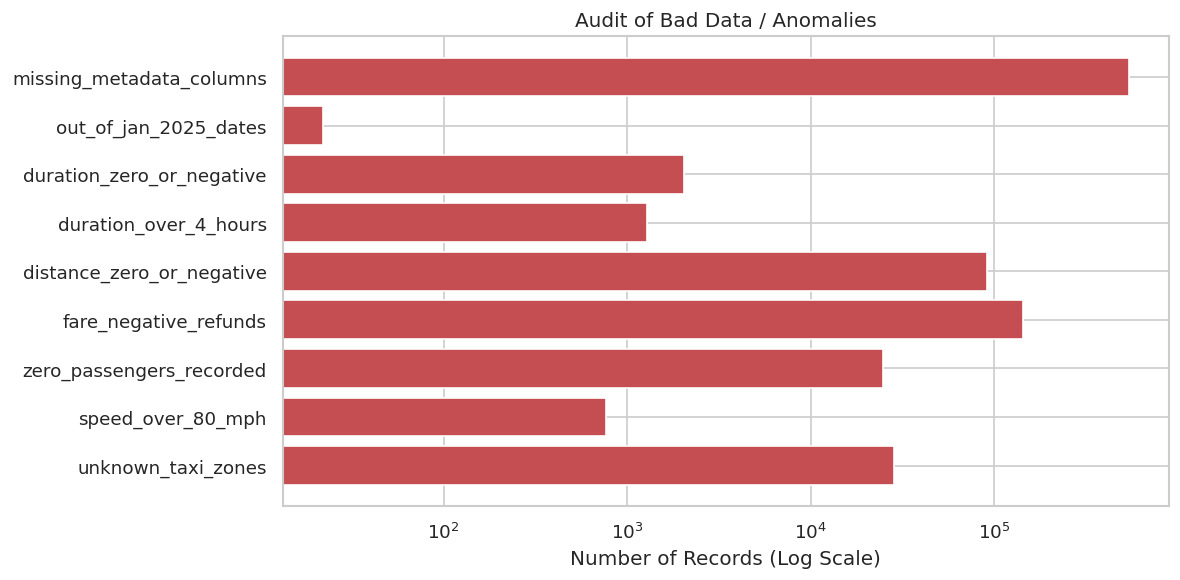

In [ ]:
# Figure 1: Data Quality Issues
labels = list(quality_issues.keys())
values = list(quality_issues.values())

plt.figure(figsize=(10, 5))
plt.barh(labels[::-1], values[::-1], color="#c44e52")
plt.xscale("log")
plt.xlabel("Number of Records (Log Scale)")
plt.title("Audit of Bad Data / Anomalies")
plt.tight_layout()
plt.savefig("figures/phase1/fig1_quality_anomalies.png")
plt.show()

In [ ]:
vars = ['trip_distance', "duration_min", 'fare_amount', 'speed_mph', 'net_flow']

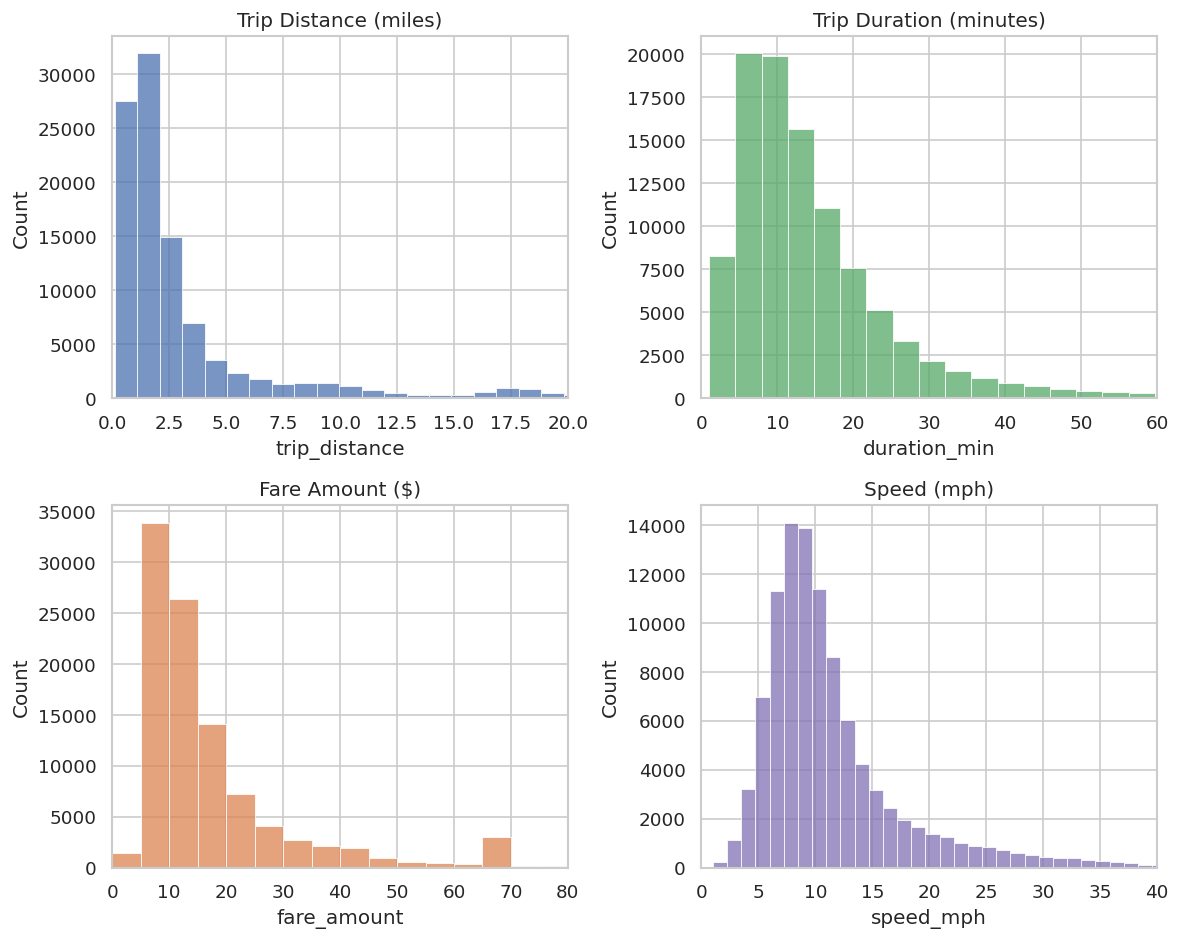

In [ ]:
# Figure 2: Univariate Distributions
# We use a random sample of 100,000 trips so the chart loads fast in Colab
sample_df = df_clean.sample(n=min(100000, len(df_clean)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.histplot(sample_df["trip_distance"], bins=50, ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set_xlim(0, 20)
axes[0, 0].set_title("Trip Distance (miles)")

sns.histplot(sample_df["duration_min"], bins=50, ax=axes[0, 1], color="#55a868")
axes[0, 1].set_xlim(0, 60)
axes[0, 1].set_title("Trip Duration (minutes)")

sns.histplot(sample_df["fare_amount"], bins=50, ax=axes[1, 0], color="#dd8452")
axes[1, 0].set_xlim(0, 80)
axes[1, 0].set_title("Fare Amount ($)")

sns.histplot(sample_df["speed_mph"], bins=50, ax=axes[1, 1], color="#8172b3")
axes[1, 1].set_xlim(0, 40)
axes[1, 1].set_title("Speed (mph)")

plt.tight_layout()
plt.savefig("figures/phase1/fig2_distributions.png")
plt.show()

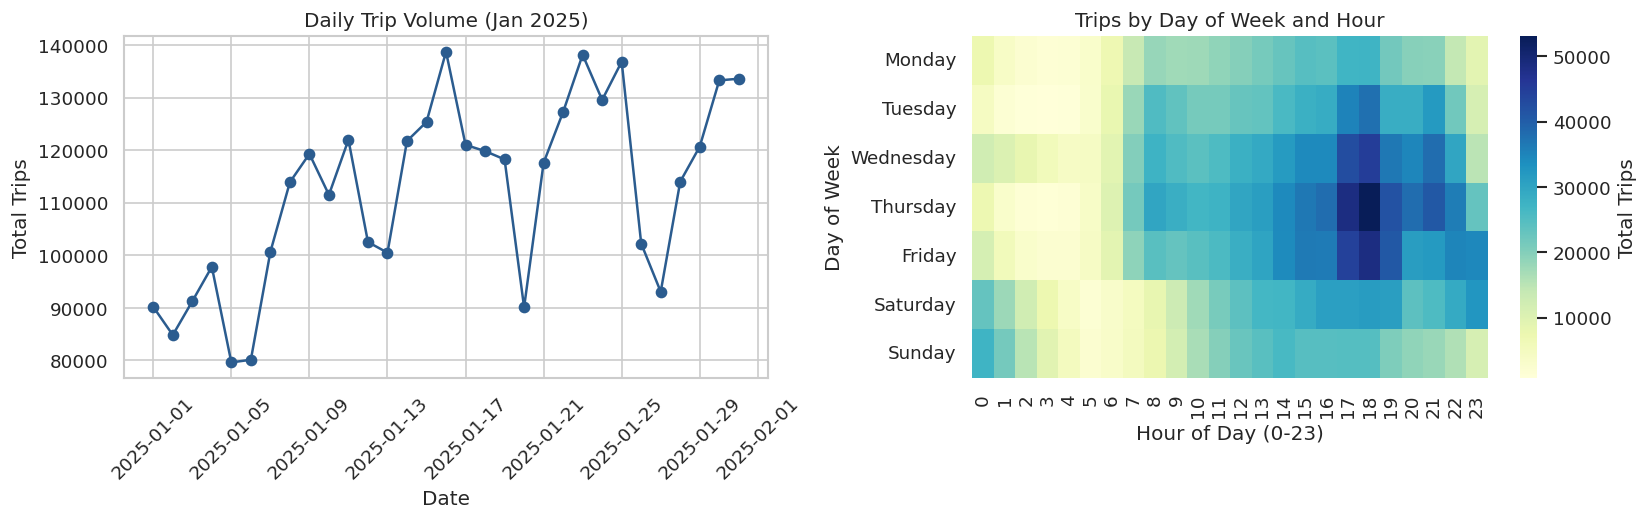

In [ ]:
# Figure 3: Daily Trend (by Date) + Heatmap (by Day of Week and Hour)
df_jan = df_flow.copy()
df_jan["date"] = df_jan["pickup_dt"].dt.date
df_jan["hour"] = df_jan["pickup_dt"].dt.hour
df_jan["day_name"] = df_jan["pickup_dt"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

daily_counts = df_jan.groupby("date").size()
pivot_dow_hour = df_jan.pivot_table(index="day_name", columns="hour", values="VendorID", aggfunc="count").reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left plot: Trips by Date
axes[0].plot(daily_counts.index, daily_counts.values, marker="o", color="#2b5c8f")
axes[0].set_title("Daily Trip Volume (Jan 2025)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total Trips")
axes[0].tick_params(axis="x", rotation=45)

# Right plot: Trips by Day of Week & Hour
sns.heatmap(pivot_dow_hour, cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "Total Trips"})
axes[1].set_title("Trips by Day of Week and Hour")
axes[1].set_xlabel("Hour of Day (0-23)")
axes[1].set_ylabel("Day of Week")

plt.tight_layout()
plt.savefig("figures/phase1/fig3_temporal_audit.png")
plt.show()

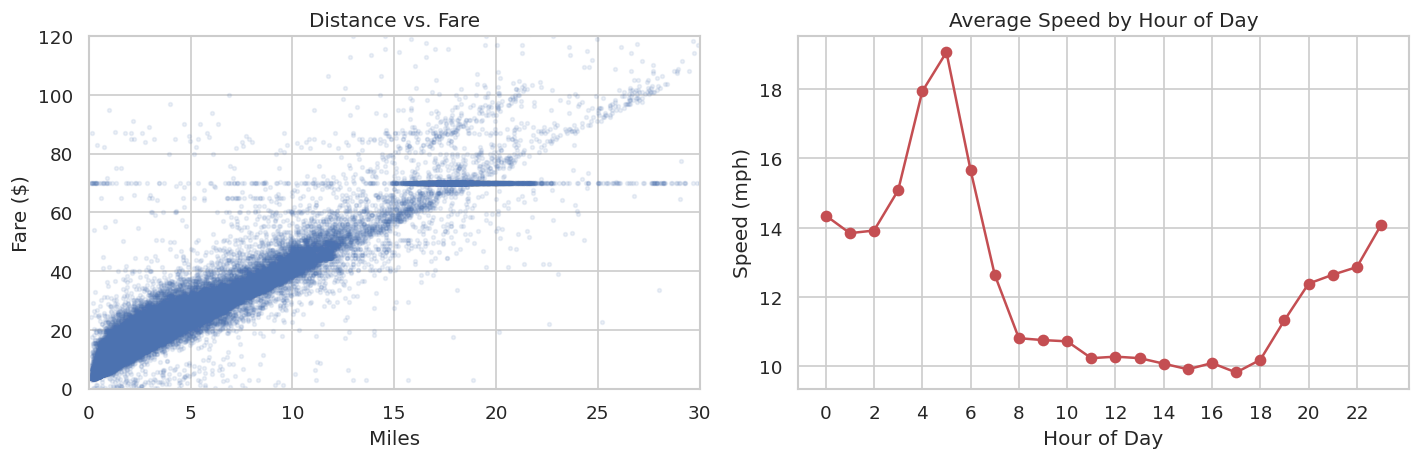

In [ ]:
# Figure 4: Variable Consistency
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot distance vs fare (Shows the $70 JFK flat fare line!)
axes[0].scatter(sample_df["trip_distance"], sample_df["fare_amount"], alpha=0.1, s=5, color="#4c72b0")
axes[0].set_xlim(0, 30)
axes[0].set_ylim(0, 120)
axes[0].set_title("Distance vs. Fare")
axes[0].set_xlabel("Miles")
axes[0].set_ylabel("Fare ($)")

# Plot average speed per hour of the day
hourly_speed = df_clean.groupby(df_clean["pickup_dt"].dt.hour)["speed_mph"].mean()
axes[1].plot(hourly_speed.index, hourly_speed.values, marker="o", color="#c44e52")
axes[1].set_title("Average Speed by Hour of Day")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Speed (mph)")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig("figures/phase1/fig4_consistency.png")
plt.show()

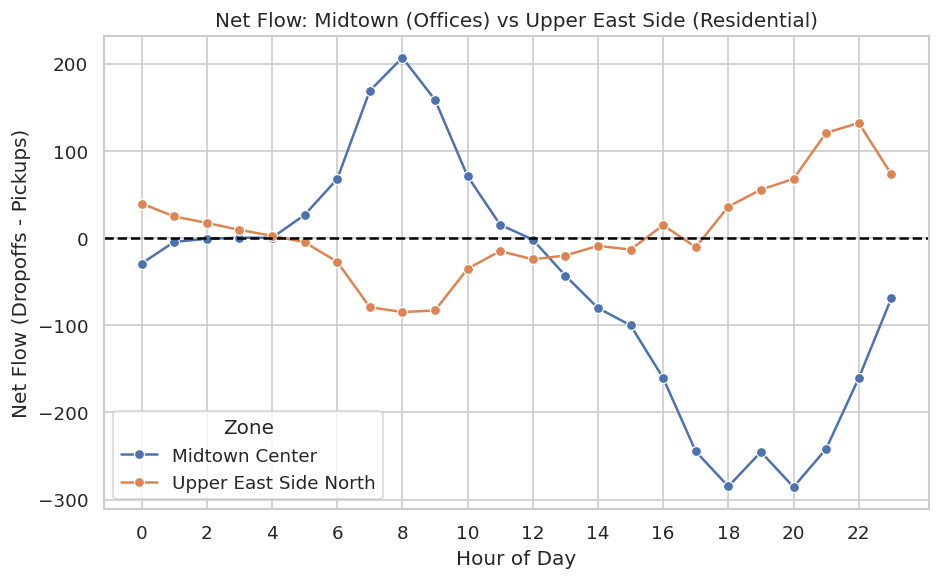

In [ ]:
# Figure 5: Net-Flow Dynamics
# 161 = Midtown Center (Offices), 236 = Upper East Side (Residential)
key_zones = panel[panel["LocationID"].isin([161, 236])].copy()
diurnal_profile = key_zones.groupby(["Zone", "hour_of_day"])["net_flow"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(data=diurnal_profile, x="hour_of_day", y="net_flow", hue="Zone", marker="o")
plt.axhline(0, color="black", linestyle="--")
plt.title("Net Flow: Midtown (Offices) vs Upper East Side (Residential)")
plt.xlabel("Hour of Day")
plt.ylabel("Net Flow (Dropoffs - Pickups)")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("figures/phase1/fig5_net_flow.png")
plt.show()

/tmp/ipykernel_2169/2615154653.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=spatial_df.head(15), y="Zone", x="pickup_count", ax=axes[0], palette="viridis")


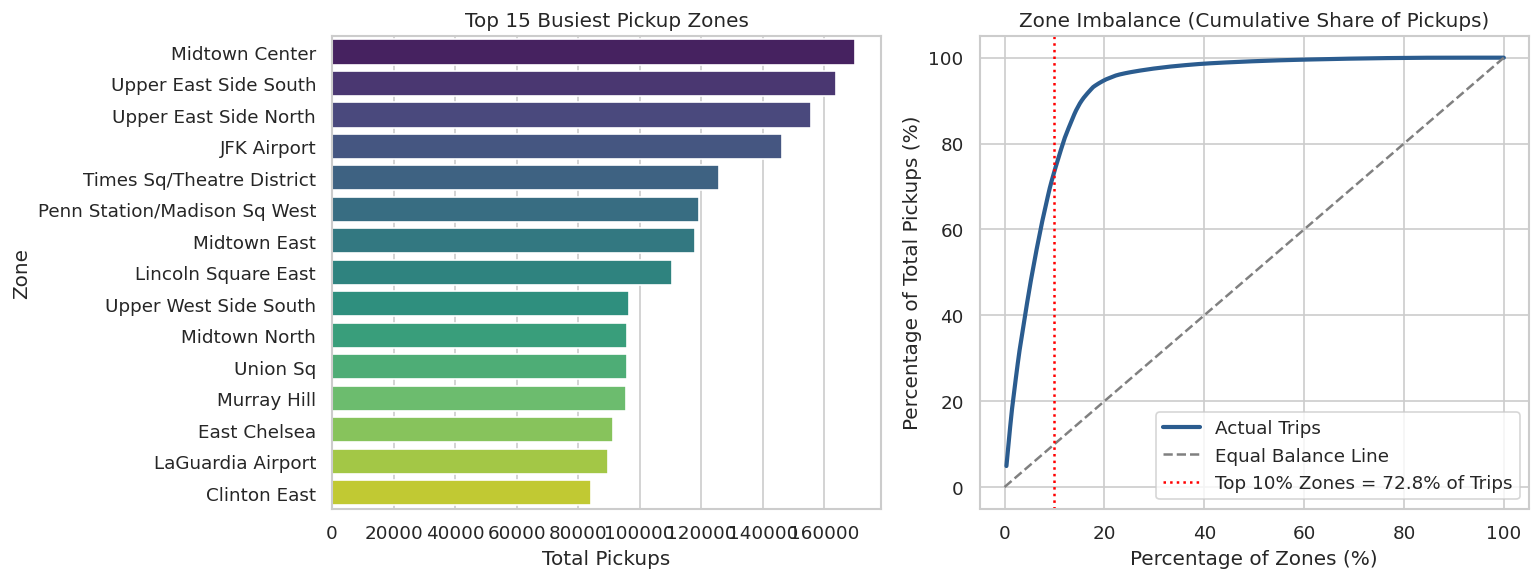

In [ ]:
# Figure 6: Top 15 Zones & Spatial Imbalance
pu_counts = df_flow["PULocationID"].value_counts().reset_index()
pu_counts.columns = ["LocationID", "pickup_count"]
spatial_df = zones.merge(pu_counts, on="LocationID", how="left").fillna(0)
spatial_df = spatial_df.sort_values("pickup_count", ascending=False)

# Calculate cumulative percentage of trips
sorted_counts = spatial_df["pickup_count"].values
cum_zones_pct = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts) * 100
cum_trips_pct = np.cumsum(sorted_counts) / sorted_counts.sum() * 100
top10_share = cum_trips_pct[int(len(sorted_counts) * 0.10) - 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Top 15 Busiest Zones
sns.barplot(data=spatial_df.head(15), y="Zone", x="pickup_count", ax=axes[0], palette="viridis")
axes[0].set_title("Top 15 Busiest Pickup Zones")
axes[0].set_xlabel("Total Pickups")
axes[0].set_ylabel("Zone")

# Right: Concentration curve showing imbalance
axes[1].plot(cum_zones_pct, cum_trips_pct, linewidth=2.5, color="#2b5c8f", label="Actual Trips")
axes[1].plot([0, 100], [0, 100], linestyle="--", color="gray", label="Equal Balance Line")
axes[1].axvline(10, color="red", linestyle=":", label=f"Top 10% Zones = {top10_share:.1f}% of Trips")
axes[1].set_title("Zone Imbalance (Cumulative Share of Pickups)")
axes[1].set_xlabel("Percentage of Zones (%)")
axes[1].set_ylabel("Percentage of Total Pickups (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/phase1/fig6_spatial_imbalance.png")
plt.show()

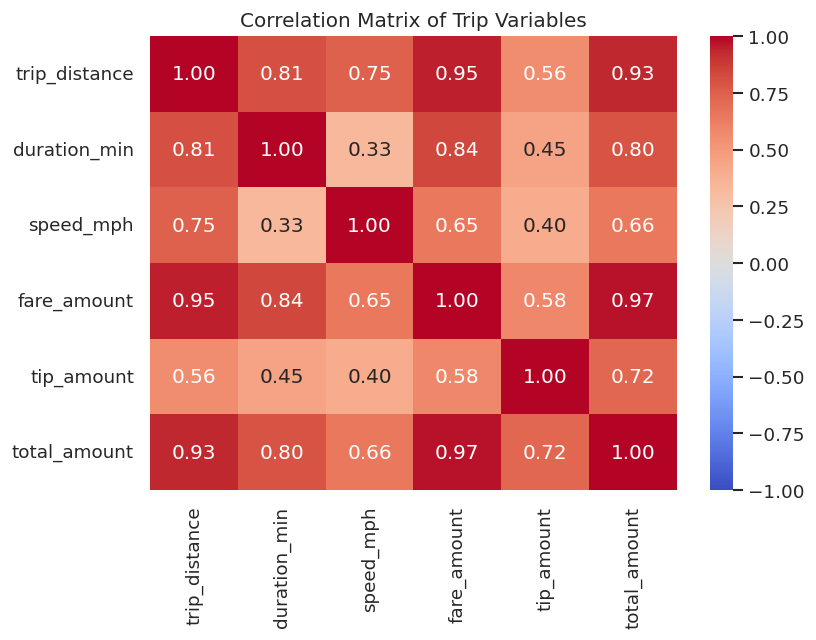

In [ ]:
# Figure 7: Correlation Heatmap
corr_cols = ["trip_distance", "duration_min", "speed_mph", "fare_amount", "tip_amount", "total_amount"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Trip Variables")
plt.tight_layout()
plt.savefig("figures/phase1/fig7_correlation.png")
plt.show()